# CNN với dataset MNIST

## 0. Chuẩn bị thư viện

In [1]:
# Nếu thiếu thư viện, bỏ dấu # và chạy một lần:
# !pip install tensorflow torch torchvision scikit-learn matplotlib

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

import random
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

print('TensorFlow:', tf.__version__)
print('PyTorch:', torch.__version__)

TensorFlow: 2.21.0
PyTorch: 2.14.0+cpu


## 1. Load dataset MNIST

Ta dùng hàm `load_data()` có sẵn trong Keras. Lần chạy đầu, thư viện có thể tự tải dữ liệu về cache của máy; những lần sau sẽ dùng lại dữ liệu đã có.

In [2]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Thêm chiều kênh màu để dữ liệu có dạng NHWC
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

class_names = [str(i) for i in range(10)]

print('x_train:', x_train.shape)
print('y_train:', y_train.shape)
print('x_test :', x_test.shape)
print('y_test :', y_test.shape)
print('Kiểu dữ liệu ảnh:', x_train.dtype)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
x_train: (60000, 28, 28, 1)
y_train: (60000,)
x_test : (10000, 28, 28, 1)
y_test : (10000,)
Kiểu dữ liệu ảnh: uint8


### Chuẩn hóa dữ liệu

Giá trị pixel ban đầu nằm trong khoảng `0 → 255`. Chia cho `255.0` để đưa dữ liệu về `0 → 1`, giúp quá trình tối ưu ổn định hơn.

In [3]:
x_train_norm = x_train.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

print('Min:', x_train_norm.min())
print('Max:', x_train_norm.max())

Min: 0.0
Max: 1.0


## 2. Khám phá dữ liệu và biểu đồ

### 2.1. Hiển thị một số ảnh mẫu

Biểu đồ dưới giúp kiểm tra trực quan xem ảnh và nhãn có khớp nhau hay không.

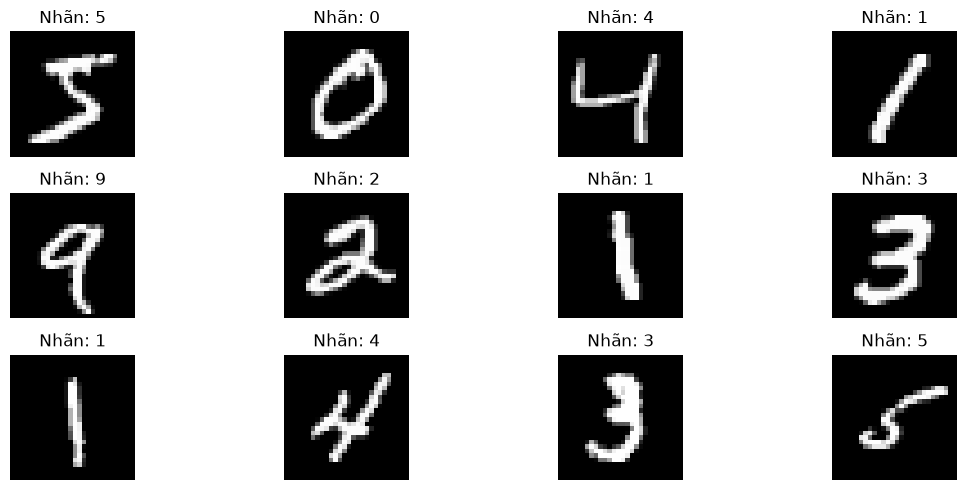

In [4]:
plt.figure(figsize=(12, 5))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    img = x_train[i]
    if img.shape[-1] == 1:
        img = img.squeeze(-1)
    plt.imshow(img, cmap='gray')
    plt.title(f'Nhãn: {class_names[int(y_train[i])]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** mỗi ô là một ảnh trong tập train kèm nhãn thật. Với MNIST, biểu đồ này dùng để xác nhận dữ liệu đã được load đúng và quan sát mức độ khó của bài toán trước khi xây dựng CNN.

### 2.2. Phân bố số lượng ảnh theo lớp

Nếu các cột có chiều cao gần nhau thì dataset tương đối cân bằng giữa các lớp.

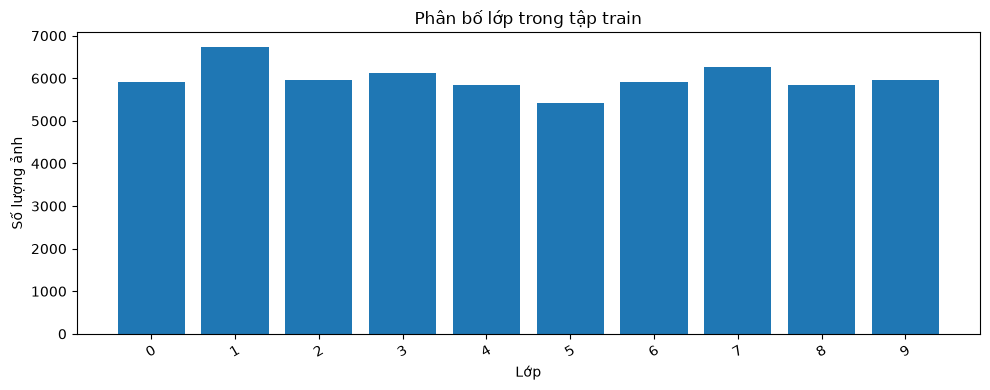

         0: 5923
         1: 6742
         2: 5958
         3: 6131
         4: 5842
         5: 5421
         6: 5918
         7: 6265
         8: 5851
         9: 5949


In [5]:
counts = np.bincount(y_train, minlength=10)

plt.figure(figsize=(10, 4))
plt.bar(class_names, counts)
plt.xlabel('Lớp')
plt.ylabel('Số lượng ảnh')
plt.title('Phân bố lớp trong tập train')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

for name, count in zip(class_names, counts):
    print(f'{name:>10}: {count}')

**Giải thích biểu đồ:** trục ngang là các lớp, trục dọc là số ảnh của từng lớp. Phân bố tương đối đồng đều giúp accuracy có ý nghĩa hơn và giảm nguy cơ mô hình chỉ học tốt các lớp xuất hiện nhiều.

# 3. CNN from scratch bằng NumPy

Trong phần này **không dùng `Conv2D`, `MaxPooling2D`, `Dense`, `Sequential` của TensorFlow hay PyTorch**. Ta tự viết các phép toán chính của CNN bằng NumPy:

`Ảnh → Convolution → ReLU → Max Pooling → Flatten → Dense → Softmax`

Để notebook chạy trong thời gian hợp lý, phần from scratch chỉ dùng một tập con của dữ liệu. Đây là phiên bản phục vụ học thuật, không nhằm cạnh tranh độ chính xác với framework tối ưu sẵn.

### 3.1. Các hàm nền tảng của CNN

- `conv_forward`: trượt kernel trên ảnh và tạo feature map.
- `relu_forward`: thay giá trị âm bằng 0.
- `maxpool_forward`: lấy giá trị lớn nhất trong từng cửa sổ `2×2`.
- `softmax_cross_entropy`: biến logits thành xác suất, tính loss và gradient.
- Các hàm `*_backward`: lan truyền gradient ngược để cập nhật trọng số.

In [6]:
class SimpleCNNNumpy:
    """CNN nhỏ: Conv(3x3) -> ReLU -> MaxPool(2x2) -> Dense(10)."""

    def __init__(self, input_channels, num_filters=8, num_classes=10, seed=42):
        rng = np.random.default_rng(seed)
        self.kh = self.kw = 3
        self.num_filters = num_filters

        # He initialization cho kernel convolution
        fan_in = self.kh * self.kw * input_channels
        self.Wc = (rng.standard_normal((self.kh, self.kw, input_channels, num_filters))
                   * np.sqrt(2.0 / fan_in)).astype(np.float32)
        self.bc = np.zeros(num_filters, dtype=np.float32)

        # Dense được khởi tạo sau lần forward đầu tiên vì lúc đó mới biết số feature
        self.Wd = None
        self.bd = np.zeros(num_classes, dtype=np.float32)
        self.num_classes = num_classes
        self.rng = rng

    def conv_forward(self, x):
        # x: (N, H, W, C)
        patches = np.lib.stride_tricks.sliding_window_view(
            x, (self.kh, self.kw), axis=(1, 2)
        )
        # patches: (N, Hout, Wout, C, kh, kw)
        out = np.einsum('nhwckl,klcf->nhwf', patches, self.Wc) + self.bc
        return out, (x, patches)

    def conv_backward(self, dout, cache):
        x, patches = cache
        Hout, Wout = dout.shape[1], dout.shape[2]

        dW = np.einsum('nhwckl,nhwf->klcf', patches, dout)
        db = dout.sum(axis=(0, 1, 2))

        dx = np.zeros_like(x)
        for i in range(self.kh):
            for j in range(self.kw):
                dx[:, i:i+Hout, j:j+Wout, :] += np.einsum(
                    'nhwf,cf->nhwc', dout, self.Wc[i, j]
                )
        return dx, dW, db

    @staticmethod
    def relu_forward(x):
        out = np.maximum(0, x)
        return out, x

    @staticmethod
    def relu_backward(dout, cache):
        x = cache
        return dout * (x > 0)

    @staticmethod
    def maxpool_forward(x):
        # Pool 2x2, stride 2. Kích thước đầu vào ở bài này chia hết cho 2.
        N, H, W, C = x.shape
        H2, W2 = H // 2, W // 2
        x_crop = x[:, :H2*2, :W2*2, :]
        x_reshape = x_crop.reshape(N, H2, 2, W2, 2, C)
        out = x_reshape.max(axis=(2, 4))
        mask = (x_reshape == out[:, :, None, :, None, :])
        return out, (x_crop.shape, mask)

    @staticmethod
    def maxpool_backward(dout, cache):
        original_shape, mask = cache
        # Nếu có nhiều phần tử cùng bằng max, chia gradient đều cho các vị trí đó
        count = mask.sum(axis=(2, 4), keepdims=True)
        dx_reshape = mask * (dout[:, :, None, :, None, :] / count)
        return dx_reshape.reshape(original_shape)

    @staticmethod
    def softmax_cross_entropy(logits, y):
        shifted = logits - logits.max(axis=1, keepdims=True)
        exp_scores = np.exp(shifted)
        probs = exp_scores / exp_scores.sum(axis=1, keepdims=True)

        n = len(y)
        loss = -np.mean(np.log(probs[np.arange(n), y] + 1e-12))

        dlogits = probs.copy()
        dlogits[np.arange(n), y] -= 1
        dlogits /= n
        return loss, probs, dlogits

    def forward(self, x):
        conv, conv_cache = self.conv_forward(x)
        relu, relu_cache = self.relu_forward(conv)
        pool, pool_cache = self.maxpool_forward(relu)

        flat = pool.reshape(pool.shape[0], -1)

        if self.Wd is None:
            fan_in = flat.shape[1]
            self.Wd = (self.rng.standard_normal((fan_in, self.num_classes))
                       * np.sqrt(2.0 / fan_in)).astype(np.float32)

        logits = flat @ self.Wd + self.bd
        cache = (conv_cache, relu_cache, pool_cache, pool.shape, flat)
        return logits, cache

    def train_batch(self, x, y, lr=0.01):
        logits, cache = self.forward(x)
        loss, probs, dlogits = self.softmax_cross_entropy(logits, y)

        conv_cache, relu_cache, pool_cache, pool_shape, flat = cache

        # Backprop Dense
        dWd = flat.T @ dlogits
        dbd = dlogits.sum(axis=0)
        dflat = dlogits @ self.Wd.T

        # Backprop Pool -> ReLU -> Conv
        dpool = dflat.reshape(pool_shape)
        drelu = self.maxpool_backward(dpool, pool_cache)
        dconv = self.relu_backward(drelu, relu_cache)
        _, dWc, dbc = self.conv_backward(dconv, conv_cache)

        # SGD update
        self.Wd -= lr * dWd
        self.bd -= lr * dbd
        self.Wc -= lr * dWc
        self.bc -= lr * dbc

        pred = probs.argmax(axis=1)
        acc = (pred == y).mean()
        return float(loss), float(acc)

    def predict(self, x, batch_size=256):
        preds = []
        for start in range(0, len(x), batch_size):
            logits, _ = self.forward(x[start:start+batch_size])
            preds.append(logits.argmax(axis=1))
        return np.concatenate(preds)

    def fit(self, x, y, x_val, y_val, epochs=4, batch_size=64, lr=0.01):
        history = {'loss': [], 'train_acc': [], 'val_acc': []}

        for epoch in range(1, epochs + 1):
            indices = self.rng.permutation(len(x))
            batch_losses = []
            batch_accs = []

            for start in range(0, len(x), batch_size):
                idx = indices[start:start+batch_size]
                loss, acc = self.train_batch(x[idx], y[idx], lr=lr)
                batch_losses.append(loss)
                batch_accs.append(acc)

            val_pred = self.predict(x_val)
            val_acc = (val_pred == y_val).mean()

            history['loss'].append(np.mean(batch_losses))
            history['train_acc'].append(np.mean(batch_accs))
            history['val_acc'].append(val_acc)

            print(
                f'Epoch {epoch:02d}/{epochs} - '
                f'loss: {history["loss"][-1]:.4f} - '
                f'train_acc: {history["train_acc"][-1]:.4f} - '
                f'val_acc: {val_acc:.4f}'
            )

        return history

### 3.2. Huấn luyện CNN from scratch

Để tránh thời gian chạy quá lâu, ta dùng **4000 ảnh train** và **1000 ảnh test** cho phần NumPy. Có thể tăng các giá trị này nếu máy đủ mạnh.

In [7]:
SCRATCH_TRAIN_SIZE = 4000
SCRATCH_TEST_SIZE = 1000
SCRATCH_EPOCHS = 4

x_scratch_train = x_train_norm[:SCRATCH_TRAIN_SIZE]
y_scratch_train = y_train[:SCRATCH_TRAIN_SIZE]
x_scratch_test = x_test_norm[:SCRATCH_TEST_SIZE]
y_scratch_test = y_test[:SCRATCH_TEST_SIZE]

scratch_model = SimpleCNNNumpy(
    input_channels=1,
    num_filters=8,
    num_classes=10,
    seed=SEED
)

scratch_history = scratch_model.fit(
    x_scratch_train,
    y_scratch_train,
    x_scratch_test,
    y_scratch_test,
    epochs=SCRATCH_EPOCHS,
    batch_size=64,
    lr=0.03
)

scratch_pred = scratch_model.predict(x_scratch_test)
scratch_acc = accuracy_score(y_scratch_test, scratch_pred)
print(f'Accuracy from scratch: {scratch_acc:.4f}')

Epoch 01/4 - loss: 1.0684 - train_acc: 0.7210 - val_acc: 0.8170
Epoch 02/4 - loss: 0.4828 - train_acc: 0.8688 - val_acc: 0.8210
Epoch 03/4 - loss: 0.3907 - train_acc: 0.8934 - val_acc: 0.8640
Epoch 04/4 - loss: 0.3471 - train_acc: 0.9023 - val_acc: 0.8450
Accuracy from scratch: 0.8450


### 3.3. Biểu đồ huấn luyện CNN from scratch

Ta theo dõi loss và accuracy qua từng epoch để biết mô hình có thật sự học hay không.

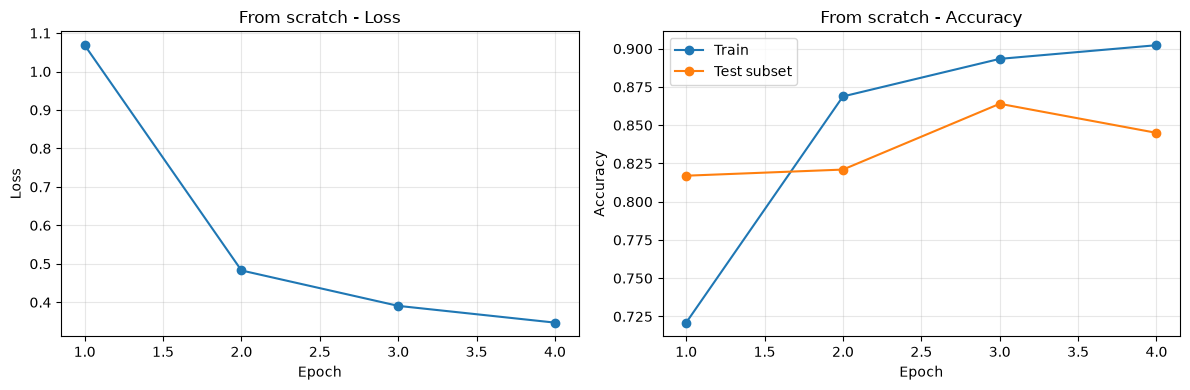

In [8]:
epochs_axis = np.arange(1, len(scratch_history['loss']) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_axis, scratch_history['loss'], marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('From scratch - Loss')
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, scratch_history['train_acc'], marker='o', label='Train')
plt.plot(epochs_axis, scratch_history['val_acc'], marker='o', label='Test subset')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('From scratch - Accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** nếu loss giảm dần và accuracy tăng dần thì gradient và quá trình cập nhật trọng số đang hoạt động đúng. Khoảng cách lớn giữa train accuracy và test accuracy có thể là dấu hiệu overfitting. Vì phiên bản from scratch chỉ dùng một phần dữ liệu và kiến trúc nhỏ nên kết quả thường thấp hơn Keras/PyTorch.

# 4. CNN bằng TensorFlow/Keras

Keras cung cấp các layer đã tối ưu sẵn. Ta xây dựng một CNN sâu hơn, train trên toàn bộ tập train và đánh giá trên tập test.

In [9]:
keras_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

In [10]:
keras_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### 4.1. Compile và huấn luyện

- Optimizer `Adam`: cập nhật trọng số dựa trên gradient.
- Loss `sparse_categorical_crossentropy`: phù hợp khi nhãn là số nguyên `0..9`.
- Metric `accuracy`: tỷ lệ dự đoán đúng.

In [11]:
keras_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

keras_history = keras_model.fit(
    x_train_norm,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.9264 - loss: 0.2396 - val_accuracy: 0.9845 - val_loss: 0.0593
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 34s 80ms/step - accuracy: 0.9787 - loss: 0.0707 - val_accuracy: 0.9873 - val_loss: 0.0444
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 32s 76ms/step - accuracy: 0.9843 - loss: 0.0503 - val_accuracy: 0.9897 - val_loss: 0.0390
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 88ms/step - accuracy: 0.9876 - loss: 0.0395 - val_accuracy: 0.9912 - val_loss: 0.0332
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 33s 79ms/step - accuracy: 0.9896 - loss: 0.0325 - val_accuracy: 0.9892 - val_loss: 0.0371


### 4.2. Biểu đồ Accuracy và Loss của Keras

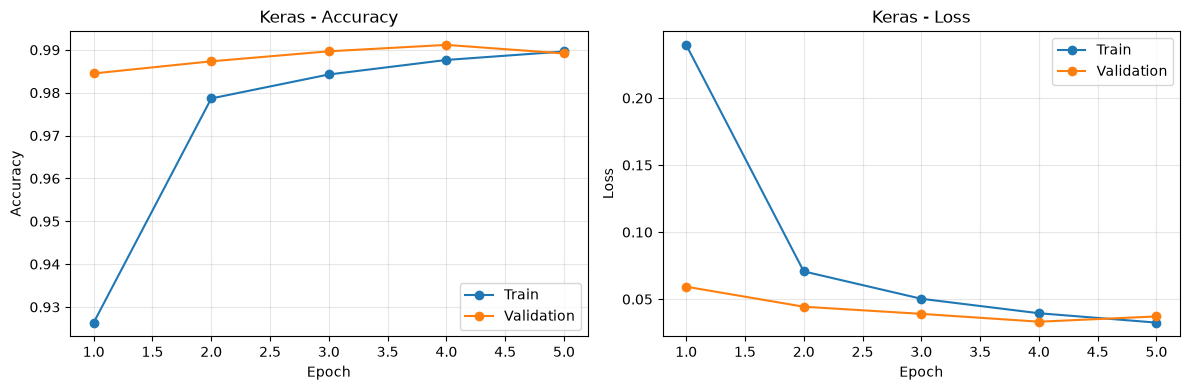

In [12]:
h = keras_history.history
epochs_axis = np.arange(1, len(h['loss']) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_axis, h['accuracy'], marker='o', label='Train')
plt.plot(epochs_axis, h['val_accuracy'], marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Keras - Accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, h['loss'], marker='o', label='Train')
plt.plot(epochs_axis, h['val_loss'], marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Keras - Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** accuracy tăng và loss giảm cho thấy mô hình đang học được đặc trưng. Nếu train accuracy tiếp tục tăng nhưng validation accuracy đứng yên hoặc validation loss tăng, mô hình bắt đầu có dấu hiệu overfitting.

### 4.3. Đánh giá Keras trên tập test và Confusion Matrix

Confusion matrix cho biết lớp thật và lớp dự đoán. Giá trị lớn trên đường chéo chính là các mẫu dự đoán đúng; các ô ngoài đường chéo thể hiện những lớp mô hình hay nhầm lẫn.

Keras test loss    : 0.0273
Keras test accuracy: 0.9908


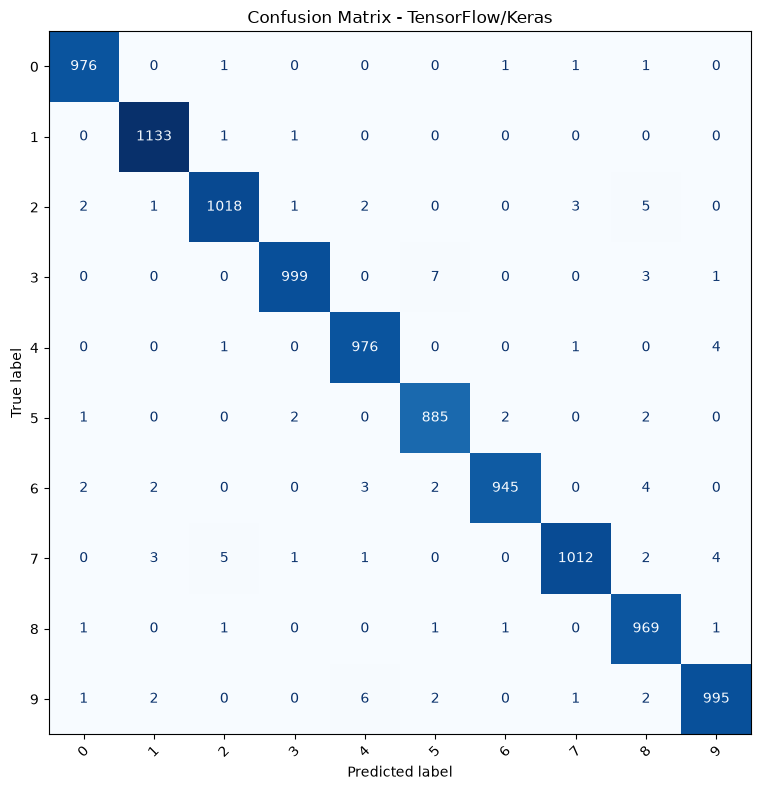

In [13]:
keras_test_loss, keras_test_acc = keras_model.evaluate(x_test_norm, y_test, verbose=0)
keras_probs = keras_model.predict(x_test_norm, verbose=0)
keras_pred = keras_probs.argmax(axis=1)

print(f'Keras test loss    : {keras_test_loss:.4f}')
print(f'Keras test accuracy: {keras_test_acc:.4f}')

cm_keras = confusion_matrix(y_test, keras_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm_keras, display_labels=class_names).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False
)
plt.title('Confusion Matrix - TensorFlow/Keras')
plt.tight_layout()
plt.show()

**Giải thích confusion matrix:** mỗi hàng tương ứng nhãn thật, mỗi cột là nhãn mô hình dự đoán. Một CNN tốt sẽ có phần lớn số lượng tập trung trên đường chéo chính. Các ô lớn ngoài đường chéo giúp xác định cụ thể hai lớp nào dễ bị nhầm với nhau.

# 5. CNN bằng PyTorch

PyTorch dùng kiểu dữ liệu `Tensor` theo thứ tự kênh `NCHW`, vì vậy ta chuyển dữ liệu từ `NHWC` sang `NCHW` trước khi tạo `DataLoader`.

In [14]:
# Chuyển NumPy NHWC -> PyTorch NCHW
x_train_t = torch.from_numpy(x_train_norm).permute(0, 3, 1, 2).float()
y_train_t = torch.from_numpy(y_train).long()
x_test_t = torch.from_numpy(x_test_norm).permute(0, 3, 1, 2).float()
y_test_t = torch.from_numpy(y_test).long()

train_dataset = TensorDataset(x_train_t, y_train_t)
test_dataset = TensorDataset(x_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=0)

print('Train batches:', len(train_loader))
print('Test batches :', len(test_loader))

Train batches: 469
Test batches : 40


### 5.1. Định nghĩa kiến trúc PyTorch

Trong PyTorch, lớp mô hình kế thừa `nn.Module` và phải định nghĩa hàm `forward()` để mô tả đường đi của dữ liệu qua mạng.

In [15]:
class TorchCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [16]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch_model = TorchCNN().to(device)
print('Thiết bị:', device)
print(torch_model)

Thiết bị: cpu
TorchCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


### 5.2. Hàm train và evaluate của PyTorch

Quy trình một batch:

`zero_grad() → forward → tính loss → backward() → optimizer.step()`

In [22]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)
        pred = logits.argmax(dim=1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)

    return total_loss / total, correct / total


def evaluate_torch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    all_pred = []
    all_true = []

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * xb.size(0)
            pred = logits.argmax(dim=1)
            correct += (pred == yb).sum().item()
            total += yb.size(0)

            all_pred.append(pred.cpu().numpy())
            all_true.append(yb.cpu().numpy())

    return (
        total_loss / total,
        correct / total,
        np.concatenate(all_true),
        np.concatenate(all_pred)
    )

### 5.3. Huấn luyện PyTorch

In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(torch_model.parameters(), lr=1e-3)

TORCH_EPOCHS = 5
torch_history = {
    'train_loss': [], 'train_acc': [],
    'test_loss': [], 'test_acc': []
}

for epoch in range(1, TORCH_EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(
        torch_model, train_loader, criterion, optimizer, device
    )
    test_loss, test_acc, _, _ = evaluate_torch(
        torch_model, test_loader, criterion, device
    )

    torch_history['train_loss'].append(train_loss)
    torch_history['train_acc'].append(train_acc)
    torch_history['test_loss'].append(test_loss)
    torch_history['test_acc'].append(test_acc)

    print(
        f'Epoch {epoch:02d}/{TORCH_EPOCHS} - '
        f'train_loss: {train_loss:.4f} - train_acc: {train_acc:.4f} - '
        f'test_loss: {test_loss:.4f} - test_acc: {test_acc:.4f}'
    )

Epoch 01/5 - train_loss: 0.0351 - train_acc: 0.9890 - test_loss: 0.0267 - test_acc: 0.9909
Epoch 02/5 - train_loss: 0.0274 - train_acc: 0.9914 - test_loss: 0.0267 - test_acc: 0.9907
Epoch 03/5 - train_loss: 0.0245 - train_acc: 0.9920 - test_loss: 0.0244 - test_acc: 0.9924
Epoch 04/5 - train_loss: 0.0205 - train_acc: 0.9934 - test_loss: 0.0247 - test_acc: 0.9924
Epoch 05/5 - train_loss: 0.0185 - train_acc: 0.9938 - test_loss: 0.0251 - test_acc: 0.9922


### 5.4. Biểu đồ huấn luyện PyTorch

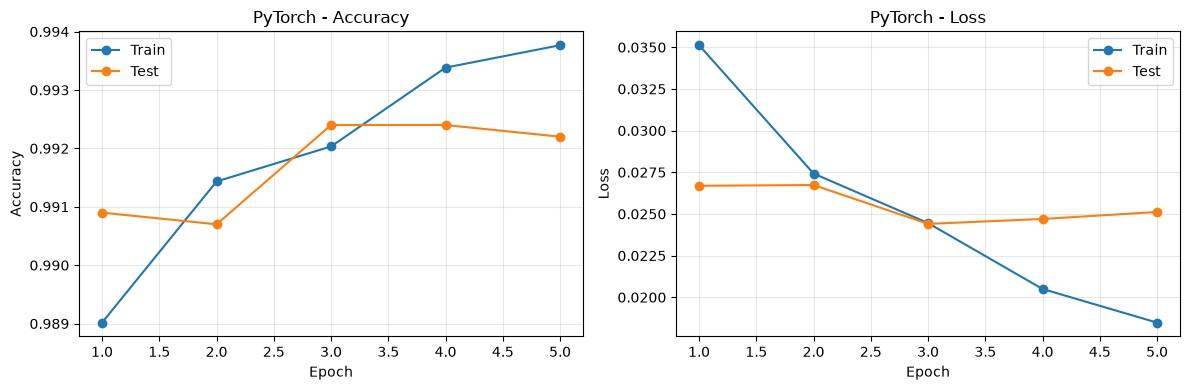

In [24]:
epochs_axis = np.arange(1, TORCH_EPOCHS + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_axis, torch_history['train_acc'], marker='o', label='Train')
plt.plot(epochs_axis, torch_history['test_acc'], marker='o', label='Test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('PyTorch - Accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, torch_history['train_loss'], marker='o', label='Train')
plt.plot(epochs_axis, torch_history['test_loss'], marker='o', label='Test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('PyTorch - Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** hai đường train và test cho biết khả năng học và tổng quát hóa của mô hình. Khi train accuracy tăng nhưng test accuracy không tăng tương ứng, cần xem xét giảm số epoch, tăng regularization hoặc dùng data augmentation.

### 5.5. Confusion Matrix của PyTorch

PyTorch test loss    : 0.0251
PyTorch test accuracy: 0.9922


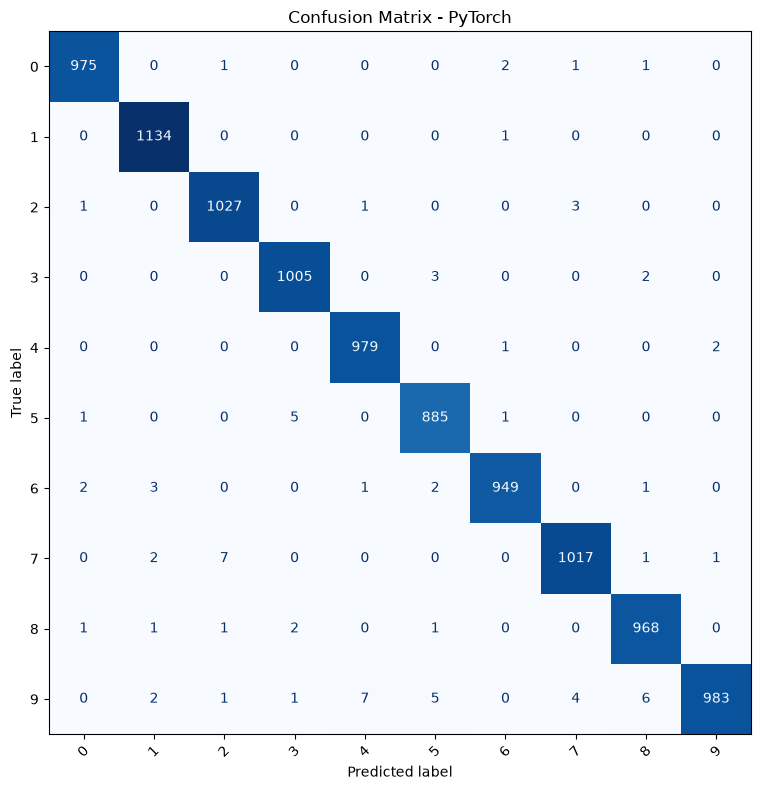

In [25]:
torch_test_loss, torch_test_acc, torch_true, torch_pred = evaluate_torch(
    torch_model, test_loader, criterion, device
)

print(f'PyTorch test loss    : {torch_test_loss:.4f}')
print(f'PyTorch test accuracy: {torch_test_acc:.4f}')

cm_torch = confusion_matrix(torch_true, torch_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm_torch, display_labels=class_names).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False
)
plt.title('Confusion Matrix - PyTorch')
plt.tight_layout()
plt.show()

**Giải thích confusion matrix:** cách đọc giống phần Keras. Các lớp có số lượng lớn ngoài đường chéo là những lớp cần phân tích thêm bằng cách xem lại ảnh dự đoán sai.

# So sánh 3 cách cài đặt

Biểu đồ cuối so sánh accuracy. Cần lưu ý **CNN from scratch chỉ train trên tập con**, còn Keras và PyTorch train trên toàn bộ tập train, nên đây là so sánh mang tính minh họa về hiệu quả triển khai chứ không phải benchmark hoàn toàn công bằng.

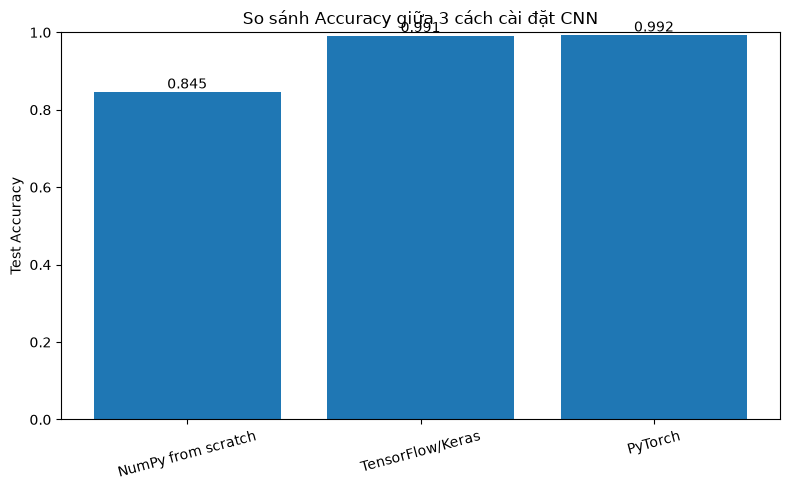

In [26]:
model_names = ['NumPy from scratch', 'TensorFlow/Keras', 'PyTorch']
accuracies = [scratch_acc, keras_test_acc, torch_test_acc]

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies)
plt.ylim(0, 1)
plt.ylabel('Test Accuracy')
plt.title('So sánh Accuracy giữa 3 cách cài đặt CNN')
plt.xticks(rotation=15)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f'{value:.3f}',
        ha='center'
    )

plt.tight_layout()
plt.show()

**Giải thích biểu đồ:** cột cao hơn tương ứng accuracy cao hơn trên dữ liệu đánh giá của từng cách. Keras và PyTorch thường đạt kết quả tốt hơn vì dùng kiến trúc sâu hơn, toàn bộ dữ liệu và các phép toán đã được tối ưu. Phần NumPy chủ yếu chứng minh cách CNN hoạt động ở mức thuật toán.

# 6. Giải thích các hàm được sử dụng

## 6.1. NumPy – CNN from scratch

| Hàm / biểu thức | Ý nghĩa |
|---|---|
| `np.lib.stride_tricks.sliding_window_view()` | Tạo các cửa sổ trượt trên ảnh để thực hiện convolution mà không cần lặp qua từng pixel bằng Python. |
| `np.einsum()` | Thực hiện phép nhân và cộng tensor; ở đây dùng để tính tích chập và gradient. |
| `np.maximum(0, x)` | Cài đặt hàm kích hoạt ReLU. |
| `reshape()` | Đổi hình dạng tensor; dùng trong pooling và flatten. |
| `argmax(axis=1)` | Lấy vị trí lớp có giá trị dự đoán lớn nhất. |
| `softmax_cross_entropy()` | Tự viết Softmax + Cross Entropy để tạo xác suất, loss và gradient. |
| `conv_backward()` | Tính gradient của kernel convolution và đầu vào. |
| `maxpool_backward()` | Đưa gradient về đúng vị trí pixel đã tạo ra giá trị max. |
| `train_batch()` | Thực hiện forward, backward và cập nhật trọng số bằng SGD cho một batch. |

## 6.2. TensorFlow/Keras

| Hàm / layer | Ý nghĩa |
|---|---|
| `Sequential()` | Tạo mô hình gồm các layer chạy tuần tự. |
| `Input(shape=...)` | Khai báo kích thước một ảnh đầu vào. |
| `Conv2D(filters, kernel_size)` | Học các kernel để trích xuất đặc trưng cục bộ như cạnh, texture và hình dạng. |
| `activation='relu'` | Áp dụng ReLU sau convolution hoặc dense. |
| `MaxPooling2D()` | Giảm kích thước feature map, giữ đặc trưng mạnh và giảm số phép tính. |
| `Flatten()` | Chuyển feature map nhiều chiều thành vector 1 chiều. |
| `Dense()` | Fully Connected layer dùng để kết hợp đặc trưng và phân loại. |
| `Dropout()` | Tắt ngẫu nhiên một phần neuron khi train để giảm overfitting. |
| `compile()` | Chọn optimizer, loss và metric. |
| `fit()` | Huấn luyện mô hình qua nhiều epoch. |
| `evaluate()` | Tính loss và metric trên dữ liệu đánh giá. |
| `predict()` | Sinh xác suất dự đoán cho từng lớp. |

## 6.3. PyTorch

| Hàm / lớp | Ý nghĩa |
|---|---|
| `nn.Module` | Lớp cơ sở cho mọi neural network trong PyTorch. |
| `forward()` | Định nghĩa dữ liệu đi qua các layer như thế nào. |
| `nn.Conv2d()` | Convolution 2D; PyTorch dùng đầu vào dạng `NCHW`. |
| `nn.ReLU()` | Hàm kích hoạt ReLU. |
| `nn.MaxPool2d()` | Max pooling 2D. |
| `nn.Flatten()` | Chuyển feature map thành vector. |
| `nn.Linear()` | Fully Connected layer. |
| `nn.Dropout()` | Regularization bằng cách tắt ngẫu nhiên neuron khi train. |
| `TensorDataset()` | Ghép tensor dữ liệu và tensor nhãn thành dataset. |
| `DataLoader()` | Chia dữ liệu thành batch, hỗ trợ shuffle khi train. |
| `nn.CrossEntropyLoss()` | Loss cho phân loại nhiều lớp; nhận trực tiếp logits nên không cần Softmax ở layer cuối. |
| `torch.optim.Adam()` | Optimizer Adam để cập nhật tham số. |
| `optimizer.zero_grad()` | Xóa gradient của batch trước. |
| `loss.backward()` | Tự động tính gradient bằng autograd. |
| `optimizer.step()` | Cập nhật trọng số theo gradient. |
| `model.train()` | Bật chế độ train, quan trọng với Dropout/BatchNorm. |
| `model.eval()` | Bật chế độ đánh giá. |
| `torch.no_grad()` | Không lưu gradient khi test, giúp tiết kiệm bộ nhớ và tăng tốc. |

## 6.4. Các khái niệm

- **Kernel/Filter:** ma trận nhỏ học cách phát hiện đặc trưng trên ảnh.
- **Feature map:** kết quả sau khi filter quét qua ảnh.
- **Stride:** số pixel kernel dịch chuyển mỗi bước.
- **Padding:** thêm biên quanh ảnh để kiểm soát kích thước feature map.
- **Epoch:** một lần mô hình đi qua toàn bộ tập train.
- **Batch:** một nhóm mẫu được xử lý trước mỗi lần cập nhật trọng số.
- **Loss:** đại lượng mô hình cố gắng giảm khi học.
- **Accuracy:** tỷ lệ số mẫu dự đoán đúng trên tổng số mẫu.
- **Backpropagation:** lan truyền gradient từ output về các layer trước để cập nhật trọng số.